# Movie Rating Classification — LRCN (CNN + LSTM) with NT-Xent Loss
## Stratified K-Fold Cross Validation Version (Movie_dataset3)

In [ ]:
!pip install tensorflow==2.21.0
!pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 134.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 95.6 MB/s eta 0:00:00
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 50.6 MB/s eta 0:00:00


In [ ]:
import os
import cv2
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers

/usr/local/lib/python3.12/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [ ]:
# -----------------------------------------------------------------------
# CONFIGURATION
# -----------------------------------------------------------------------
SEED              = 27
IMAGE_HEIGHT      = 64
IMAGE_WIDTH       = 64
SEQUENCE_LENGTH   = 20
OVERLAP           = 10
DATASET_DIR       = "Movie_datasetV3"
CLASSES_LIST      = ["G", "PG", "PG-13", "R"]
VIDEO_EXTENSIONS  = (".mp4", ".wmv", ".avi", ".mkv", ".mov", ".mpg", ".mpeg", ".flv", ".m4v")
N_SPLITS          = 3

# Pre-training
PRETRAIN_EPOCHS   = 20
PRETRAIN_PATIENCE = 5     # early-stopping patience for pre-training
TEMPERATURE       = 0.1

# Fine-tuning  (single-stage — encoder fully trainable from the start)
FINETUNE_EPOCHS   = 100
FINETUNE_LR       = 6e-4   # single LR for full model
FINETUNE_PATIENCE = 10     # generous patience — minority classes need more epochs
BATCH_SIZE        = 16

# Regularisation
L2_WEIGHT         = 5e-4   # strong L2 for small dataset
DROPOUT_AFTER_GAP = 0.5    # dropout after GlobalAveragePooling3D
DROPOUT_AFTER_ATT = 0.3    # dropout after temporal attention

# Focal loss
FOCAL_GAMMA       = 2.0    # focusing parameter — higher = more focus on hard examples
FOCAL_ALPHA       = 0.25   # base class weight factor

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# -----------------------------------------------------------------------
# Get the dataset onto the Colab filesystem
#
# This handles three common cases so you don't have to edit code by hand:
#   1. Movie_dataset3/ was already uploaded/extracted straight into the
#      Colab runtime (e.g. via the Files pane) — nothing to do.
#   2. Movie_dataset3.zip or Movie_dataset3.rar sits in your Google Drive
#      root (MyDrive/) — it gets extracted automatically.
#   3. Neither is found — you'll get a clear error telling you what to fix.
#
# If your archive lives in a Drive subfolder, just change ARCHIVE_DIR below.
# -----------------------------------------------------------------------
import os

if not os.path.isdir(DATASET_DIR):
    from google.colab import drive
    drive.mount('/content/gdrive')

    ARCHIVE_DIR = 'gdrive/MyDrive'   # change if your archive is in a subfolder
    zip_path = os.path.join(ARCHIVE_DIR, f'{DATASET_DIR}.zip')
    rar_path = os.path.join(ARCHIVE_DIR, f'{DATASET_DIR}.rar')

    if os.path.exists(zip_path):
        print(f'Found {zip_path} — extracting...')
        !unzip -q "{zip_path}"
    elif os.path.exists(rar_path):
        print(f'Found {rar_path} — extracting...')
        !unrar x "{rar_path}"
    else:
        raise FileNotFoundError(
            f"Couldn't find '{DATASET_DIR}/' locally, nor "
            f"'{DATASET_DIR}.zip' / '{DATASET_DIR}.rar' under {ARCHIVE_DIR}. "
            f"Upload the dataset to Colab, or place a zip/rar archive named "
            f"'{DATASET_DIR}' in {ARCHIVE_DIR} (or update ARCHIVE_DIR above)."
        )
else:
    print(f'{DATASET_DIR}/ already present — skipping mount/extract.')

# Sanity check: confirm every expected class folder exists
for cls in CLASSES_LIST:
    cls_dir = os.path.join(DATASET_DIR, cls)
    if not os.path.isdir(cls_dir):
        print(f'  ⚠ WARNING: expected class folder not found: {cls_dir}')
    else:
        n_videos = sum(
            1 for f in os.listdir(cls_dir)
            if f.lower().endswith(VIDEO_EXTENSIONS)
        )
        print(f'  {cls:6s}: {n_videos} video file(s) found in {cls_dir}')

Mounted at /content/gdrive
Found gdrive/MyDrive/Movie_datasetV3.rar — extracting...

UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from gdrive/MyDrive/Movie_datasetV3.rar

Creating    Movie_datasetV3                                           OK
Creating    Movie_datasetV3/G                                         OK
Extracting  Movie_datasetV3/G/G_1.mp4                                      0%  1%  OK 
Extracting  Movie_datasetV3/G/G_10.mp4                                     1%  OK 
Extracting  Movie_datasetV3/G/G_11.mp4                                     1%  OK 
Extracting  Movie_datasetV3/G/G_12.mp4                                     1%  OK 
Extracting  Movie_datasetV3/G/G_13.mp4                                     2%  OK 
Extracting  Movie_datasetV3/G/G_14.mp4                                     2%  OK 
Extracting  Movie_datasetV3/G/G_15.mp4                                     2%

## 1. Data Loading & Preprocessing

In [ ]:
# -----------------------------------------------------------------------
# Frame Extraction
# -----------------------------------------------------------------------
def frames_extraction(video_path, sequence_length=SEQUENCE_LENGTH, overlap=0):
    sequences = []
    video_reader = cv2.VideoCapture(video_path)

    if not video_reader.isOpened():
        print(f"  ⚠ Skipping (couldn't open): {video_path}")
        video_reader.release()
        return sequences

    video_frames_count = int(video_reader.get(cv2.CAP_PROP_FRAME_COUNT))

    # Fallback for containers that report 0/garbage frame counts
    if video_frames_count <= 0:
        count = 0
        while True:
            success, _ = video_reader.read()
            if not success:
                break
            count += 1
        video_frames_count = count
        video_reader.release()
        video_reader = cv2.VideoCapture(video_path)

    if video_frames_count < sequence_length:
        video_reader.release()
        return sequences

    skip_frames_window = max(int(video_frames_count / sequence_length), 1)

    for start_frame in range(0, video_frames_count - sequence_length + 1, sequence_length - overlap):
        frames = []
        for frame_counter in range(sequence_length):
            video_reader.set(cv2.CAP_PROP_POS_FRAMES, start_frame + frame_counter * skip_frames_window)
            success, frame = video_reader.read()
            if not success:
                break
            resized_frame = cv2.resize(frame, (IMAGE_HEIGHT, IMAGE_WIDTH))
            normalized_frame = resized_frame / 255.0
            frames.append(normalized_frame)
        if len(frames) == sequence_length:
            sequences.append(frames)

    video_reader.release()
    return sequences


# -----------------------------------------------------------------------
# Data Augmentation
# -----------------------------------------------------------------------
def augment_frame(frame):
    # Geometric
    frame = tf.image.random_flip_left_right(frame)
    frame = tf.image.random_flip_up_down(frame)
    # Colour / photometric
    frame = tf.image.random_brightness(frame, max_delta=0.2)
    frame = tf.image.random_contrast(frame, lower=0.8, upper=1.2)
    frame = tf.image.random_saturation(frame, lower=0.8, upper=1.2)
    frame = tf.image.random_hue(frame, max_delta=0.1)
    # Clip to valid range after colour jitter
    frame = tf.clip_by_value(frame, 0.0, 1.0)
    return frame

def augment_sequence(seq):
    return [augment_frame(tf.convert_to_tensor(f, dtype=tf.float32)).numpy() for f in seq]

In [ ]:
features          = []   # shape: (N, SEQUENCE_LENGTH, H, W, 3)
labels            = []   # int class index
video_files_paths = []
skipped_files     = []

for class_index, class_name in enumerate(CLASSES_LIST):
    print(f'Extracting Data of Class: {class_name}')
    class_dir = os.path.join(DATASET_DIR, class_name)
    file_list = sorted(
        f for f in os.listdir(class_dir)
        if f.lower().endswith(VIDEO_EXTENSIONS)
    )
    print(f'  {len(file_list)} video file(s) to process')

    for file_name in file_list:
        video_path = os.path.join(class_dir, file_name)
        try:
            sequences = frames_extraction(video_path)
        except Exception as e:
            print(f"  ⚠ Skipping (error while reading): {video_path} — {e}")
            skipped_files.append(video_path)
            continue

        if len(sequences) == 0:
            skipped_files.append(video_path)
            continue

        for seq in sequences:
            if len(seq) == SEQUENCE_LENGTH:
                features.append(seq)
                labels.append(class_index)
                video_files_paths.append(video_path)

features          = np.array(features,          dtype=np.float32)
labels            = np.array(labels,            dtype=np.int32)
video_files_paths = np.array(video_files_paths)

print(f"\nTotal sequences loaded: {len(features)}")
print(f"Class distribution   : {np.bincount(labels, minlength=len(CLASSES_LIST))}")
if skipped_files:
    print(f"\n{len(skipped_files)} file(s) skipped (unreadable or too short):")
    for f in skipped_files:
        print(f"  - {f}")

Extracting Data of Class: G
  82 video file(s) to process
Extracting Data of Class: PG
  80 video file(s) to process
Extracting Data of Class: PG-13
  80 video file(s) to process
Extracting Data of Class: R
  81 video file(s) to process

Total sequences loaded: 415
Class distribution   : [ 97  98  98 122]

1 file(s) skipped (unreadable or too short):
  - Movie_datasetV3/R/R_28.wmv


## 2. Model Architecture

In [ ]:
import keras # Import keras module
import keras.ops as ops # Import keras.ops for Keras native operations

# -----------------------------------------------------------------------
# LRCN — Long-term Recurrent Convolutional Network (TimeDistributed CNN + BiLSTM)
# -----------------------------------------------------------------------
def td_conv_block(x, filters, block_id):
    """One TimeDistributed Conv2D -> BN -> ReLU -> MaxPool block, applied
    independently to every frame in the sequence."""
    x = layers.TimeDistributed(
        layers.Conv2D(filters, (3, 3), padding='same', use_bias=False,
                       kernel_regularizer=regularizers.l2(L2_WEIGHT)),
        name=f'td_conv{block_id}')(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f'td_bn{block_id}')(x)
    x = layers.TimeDistributed(layers.ReLU(), name=f'td_relu{block_id}')(x)
    x = layers.TimeDistributed(layers.MaxPooling2D((2, 2), padding='same'),
                                name=f'td_pool{block_id}')(x)
    return x


def build_lrcn_contextual(input_shape=(SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, 3),
                            lstm_units=128):
    """Returns a fresh (untrained) LRCN encoder: a per-frame CNN feature
    extractor feeding a stacked Bidirectional LSTM that outputs a single
    embedding vector per video sequence."""
    inputs = layers.Input(shape=input_shape)

    # ── TimeDistributed CNN feature extractor (per-frame, weight-shared) ──
    x = td_conv_block(inputs, 32,  block_id=1)
    x = td_conv_block(x,      64,  block_id=2)
    x = td_conv_block(x,      128, block_id=3)
    x = td_conv_block(x,      256, block_id=4)

    # Per-frame global pooling → (batch, seq_len, 256)
    x = layers.TimeDistributed(layers.GlobalAveragePooling2D(), name='td_gap')(x)
    x = layers.TimeDistributed(layers.Dropout(DROPOUT_AFTER_GAP), name='td_dropout')(x)  # ← dropout 1

    # ── Temporal modelling: stacked Bidirectional LSTM ──────────────────
    x = layers.Bidirectional(
        layers.LSTM(lstm_units, return_sequences=True,
                    kernel_regularizer=regularizers.l2(L2_WEIGHT)),
        name='bilstm1')(x)
    x = layers.Bidirectional(
        layers.LSTM(lstm_units, return_sequences=False,
                    kernel_regularizer=regularizers.l2(L2_WEIGHT)),
        name='bilstm2')(x)

    x = layers.Dropout(DROPOUT_AFTER_ATT)(x)          # ← dropout 2

    return models.Model(inputs, x)


def build_classification_model(base_model, num_classes=len(CLASSES_LIST)):
    """Adds a softmax classification head on top of the encoder."""
    outputs = Dense(num_classes, activation='softmax')(base_model.output)
    return models.Model(inputs=base_model.input, outputs=outputs)

## 3. Contrastive Learning Components

In [ ]:
# -----------------------------------------------------------------------
# NT-Xent Contrastive Loss
# -----------------------------------------------------------------------
def nt_xent_loss(z_i, z_j, temperature=TEMPERATURE):
    z_i = tf.math.l2_normalize(z_i, axis=1)
    z_j = tf.math.l2_normalize(z_j, axis=1)
    representations = tf.concat([z_i, z_j], axis=0)
    similarity_matrix = tf.matmul(representations, representations, transpose_b=True)
    batch_size = tf.shape(z_i)[0]
    labels_pos = tf.concat([tf.range(batch_size) + batch_size, tf.range(batch_size)], axis=0)
    labels_oh  = tf.one_hot(labels_pos, depth=2 * batch_size)
    mask       = tf.eye(2 * batch_size)
    similarity_matrix = similarity_matrix / temperature
    logits = similarity_matrix - mask * 1e9
    loss   = tf.nn.softmax_cross_entropy_with_logits(labels_oh, logits)
    return tf.reduce_mean(loss)


# -----------------------------------------------------------------------
# Focal Loss  — replaces categorical_crossentropy in fine-tuning
# -----------------------------------------------------------------------
def focal_loss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA):
    def loss_fn(y_true, y_pred):
        # Clip predictions for numerical stability
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

        # Standard cross-entropy per class
        ce = -y_true * tf.math.log(y_pred)

        # pt = probability of the correct class
        pt = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)

        # Focal weight: (1 - pt)^gamma — low for easy samples, high for hard
        focal_weight = alpha * tf.pow(1.0 - pt, gamma)

        # Apply focal weight to cross-entropy
        focal_ce = focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(focal_ce, axis=-1))
    return loss_fn



# -----------------------------------------------------------------------
# Contextual Pair Mining  (train split only)
# -----------------------------------------------------------------------
def create_contextual_contrastive_pairs(features, video_paths):
    contrastive_pairs = []
    for i in range(len(features)):
        current_seq   = features[i]
        current_video = video_paths[i]

        # Positive pair: two independent augmentations of the same sequence
        aug1 = augment_sequence(current_seq)
        aug2 = augment_sequence(current_seq)
        contrastive_pairs.append((aug1, aug2))

        # Contextual neighbours (same video, adjacent segments)
        if i > 0 and video_paths[i - 1] == current_video:
            contrastive_pairs.append((current_seq, features[i - 1]))
        if i < len(features) - 1 and video_paths[i + 1] == current_video:
            contrastive_pairs.append((current_seq, features[i + 1]))

    return contrastive_pairs


# -----------------------------------------------------------------------
# Contrastive Pre-training  — with best-weight checkpointing
# -----------------------------------------------------------------------
def pretrain_contrastive(model, features, video_paths,
                          epochs=PRETRAIN_EPOCHS, batch_size=32,
                          patience=PRETRAIN_PATIENCE):
    optimizer        = tf.keras.optimizers.Adam()
    epoch_losses     = []
    best_loss        = float('inf')
    best_weights     = None
    best_epoch       = 0
    patience_counter = 0

    for epoch in range(epochs):
        pairs = create_contextual_contrastive_pairs(features, video_paths)
        random.shuffle(pairs)
        batch_losses = []

        for i in range(0, len(pairs), batch_size):
            batch = pairs[i : i + batch_size]
            if len(batch) == 0:
                continue
            seq1 = tf.convert_to_tensor([p[0] for p in batch], dtype=tf.float32)
            seq2 = tf.convert_to_tensor([p[1] for p in batch], dtype=tf.float32)

            with tf.GradientTape() as tape:
                z_i  = model(seq1, training=True)
                z_j  = model(seq2, training=True)
                loss = nt_xent_loss(z_i, z_j)

            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))
            batch_losses.append(loss.numpy())

        avg = np.mean(batch_losses)
        epoch_losses.append(avg)

        # ── Best-weight checkpoint ───────────────────────────────────
        if avg < best_loss:
            best_loss        = avg
            best_weights     = model.get_weights()   # snapshot
            best_epoch       = epoch + 1
            patience_counter = 0
            tag = '  ✓ best'
        else:
            patience_counter += 1
            tag = f'  (no improvement {patience_counter}/{patience})'

        print(f"  Pretrain Epoch {epoch+1:3d}/{epochs} — Loss: {avg:.4f}{tag}")

        # ── Early stopping ───────────────────────────────────────────
        if patience_counter >= patience:
            print(f"  Early stopping triggered at epoch {epoch+1}")
            break

    # ── Restore best weights before handing encoder to fine-tuning ──
    if best_weights is not None:
        model.set_weights(best_weights)
        print(f"  Best pre-train loss: {best_loss:.4f} (epoch {best_epoch}) — weights restored ✓")

    return epoch_losses

## 5. Stratified K-Fold Cross Validation Loop

In [ ]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# -----------------------------------------------------------------------
# Storage for per-fold results
# -----------------------------------------------------------------------
fold_metrics       = []
fold_histories     = []
fold_pretrain_loss = []
all_y_true         = []
all_y_pred         = []
all_y_probs        = []

# -----------------------------------------------------------------------
# Main K-Fold Loop
# -----------------------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(skf.split(features, labels)):
    print(f"\n{'='*60}")
    print(f"  FOLD {fold+1} / {N_SPLITS}")
    print(f"{'='*60}")

    # ── Splits ────────────────────────────────────────────────────────
    X_train     = features[train_idx]
    y_train_int = labels[train_idx]
    vp_train    = video_files_paths[train_idx]
    X_test      = features[test_idx]
    y_test      = labels[test_idx]

    print(f"  Train dist : {np.bincount(y_train_int, minlength=len(CLASSES_LIST))}")
    print(f"  Test  dist : {np.bincount(y_test, minlength=len(CLASSES_LIST))}")

    # ── Class weights — penalise minority class errors more heavily ───
    cw_values = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train_int),
        y=y_train_int
    )
    class_weight_dict = dict(enumerate(cw_values))
    print(f"  Class weights: { {CLASSES_LIST[k]: round(v,2) for k,v in class_weight_dict.items()} }")

    # One-hot encode
    y_train_oh = to_categorical(y_train_int, num_classes=len(CLASSES_LIST))
    y_test_oh  = to_categorical(y_test,      num_classes=len(CLASSES_LIST))

    # ── Build a FRESH model for this fold ─────────────────────────────
    tf.keras.backend.clear_session()
    encoder = build_lrcn_contextual()

    # ── Contrastive Pre-training (training fold only) ─────────────────
    print("\n  [Pre-training — NT-Xent contrastive loss]")
    pt_losses = pretrain_contrastive(
        encoder, X_train, vp_train,
        epochs=PRETRAIN_EPOCHS, batch_size=32
    )
    fold_pretrain_loss.append(pt_losses)

    # ── Single-stage Fine-tuning ───────────────────────────────────────
    print("\n  [Fine-tuning — single stage, class-weighted loss]")

    final_model = build_classification_model(encoder, num_classes=len(CLASSES_LIST))

    lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=FINETUNE_LR,
        decay_steps=FINETUNE_EPOCHS * max(1, len(X_train) // BATCH_SIZE),
        alpha=1e-6
    )

    final_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
        loss=focal_loss(),              # replaces categorical_crossentropy
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )

    early_stop = EarlyStopping(
        monitor='val_loss', patience=FINETUNE_PATIENCE,
        restore_best_weights=True, verbose=1
    )

    history = final_model.fit(
        X_train, y_train_oh,
        validation_data=(X_test, y_test_oh),   # ← test fold as val: guaranteed minority samples
        batch_size=BATCH_SIZE,
        epochs=FINETUNE_EPOCHS,
        shuffle=True,
        class_weight=class_weight_dict,         # ← penalise minority errors more
        callbacks=[early_stop],
        verbose=1
    )
    fold_histories.append(history.history)

    # ── Evaluation on test fold ────────────────────────────────────────
    test_loss, test_acc, test_prec, test_rec = final_model.evaluate(
        X_test, y_test_oh, verbose=0
    )
    f1 = (2 * test_prec * test_rec) / (test_prec + test_rec + 1e-7)

    y_probs = final_model.predict(X_test, verbose=0)
    y_pred  = np.argmax(y_probs, axis=1)

    try:
        auc = roc_auc_score(y_test_oh, y_probs, multi_class='ovr', average='macro')
    except ValueError:
        auc = float('nan')

    fold_metrics.append({
        'fold'     : fold + 1,
        'loss'     : test_loss,
        'accuracy' : test_acc,
        'precision': test_prec,
        'recall'   : test_rec,
        'f1'       : f1,
        'auc'      : auc
    })

    all_y_true.extend(y_test.tolist())
    all_y_pred.extend(y_pred.tolist())
    all_y_probs.append(y_probs)

    print(f"\n  Fold {fold+1} Results:")
    print(f"    Accuracy : {test_acc:.4f}")
    print(f"    Precision: {test_prec:.4f}")
    print(f"    Recall   : {test_rec:.4f}")
    print(f"    F1       : {f1:.4f}")
    print(f"    AUC      : {auc:.4f}")

print("\n" + "="*60)
print("  ALL FOLDS COMPLETE")
print("="*60)


  FOLD 1 / 3
  Train dist : [64 66 65 81]
  Test  dist : [33 32 33 41]
  Class weights: {'G': np.float64(1.08), 'PG': np.float64(1.05), 'PG-13': np.float64(1.06), 'R': np.float64(0.85)}

  [Pre-training — NT-Xent contrastive loss]
  Pretrain Epoch   1/20 — Loss: 1.8408  ✓ best
  Pretrain Epoch   2/20 — Loss: 1.2069  ✓ best
  Pretrain Epoch   3/20 — Loss: 1.0213  ✓ best
  Pretrain Epoch   4/20 — Loss: 0.8308  ✓ best
  Pretrain Epoch   5/20 — Loss: 0.8286  ✓ best
  Pretrain Epoch   6/20 — Loss: 0.7688  ✓ best
  Pretrain Epoch   7/20 — Loss: 0.7454  ✓ best
  Pretrain Epoch   8/20 — Loss: 0.6840  ✓ best
  Pretrain Epoch   9/20 — Loss: 0.6877  (no improvement 1/5)
  Pretrain Epoch  10/20 — Loss: 0.7081  (no improvement 2/5)
  Pretrain Epoch  11/20 — Loss: 0.6142  ✓ best
  Pretrain Epoch  12/20 — Loss: 0.6059  ✓ best
  Pretrain Epoch  13/20 — Loss: 0.6204  (no improvement 1/5)
  Pretrain Epoch  14/20 — Loss: 0.5742  ✓ best
  Pretrain Epoch  15/20 — Loss: 0.5831  (no improvement 1/5)
  Pretr


  Fold 3 Results:
    Accuracy : 0.8188
    Precision: 0.8321
    Recall   : 0.7899
    F1       : 0.8104
    AUC      : 0.9453

  ALL FOLDS COMPLETE


## 6. Aggregated Results (Mean ± Std across folds)

In [ ]:
metrics_keys = ['accuracy', 'precision', 'recall', 'f1', 'auc']

print("\n" + "="*50)
print(" CROSS-VALIDATION SUMMARY (Mean ± Std)")
print("="*50)
for k in metrics_keys:
    vals = [m[k] for m in fold_metrics]
    print(f"  {k.capitalize():10s}: {np.mean(vals):.4f} ± {np.std(vals):.4f}")
print("="*50)

# Per-fold table
print("\nPer-fold breakdown:")
print(f"{'Fold':>5} | {'Accuracy':>9} | {'Precision':>9} | {'Recall':>7} | {'F1':>7} | {'AUC':>7}")
print("-" * 60)
for m in fold_metrics:
    print(f"{m['fold']:>5} | {m['accuracy']:>9.4f} | {m['precision']:>9.4f} | "
          f"{m['recall']:>7.4f} | {m['f1']:>7.4f} | {m['auc']:>7.4f}")


 CROSS-VALIDATION SUMMARY (Mean ± Std)
  Accuracy  : 0.7638 ± 0.0689
  Precision : 0.7924 ± 0.0560
  Recall    : 0.7469 ± 0.0568
  F1        : 0.7690 ± 0.0565
  Auc       : 0.9258 ± 0.0200

Per-fold breakdown:
 Fold |  Accuracy | Precision |  Recall |      F1 |     AUC
------------------------------------------------------------
    1 |    0.8058 |    0.8321 |  0.7842 |  0.8074 |  0.9339
    2 |    0.6667 |    0.7132 |  0.6667 |  0.6891 |  0.8983
    3 |    0.8188 |    0.8321 |  0.7899 |  0.8104 |  0.9453


## 7. Visualisations

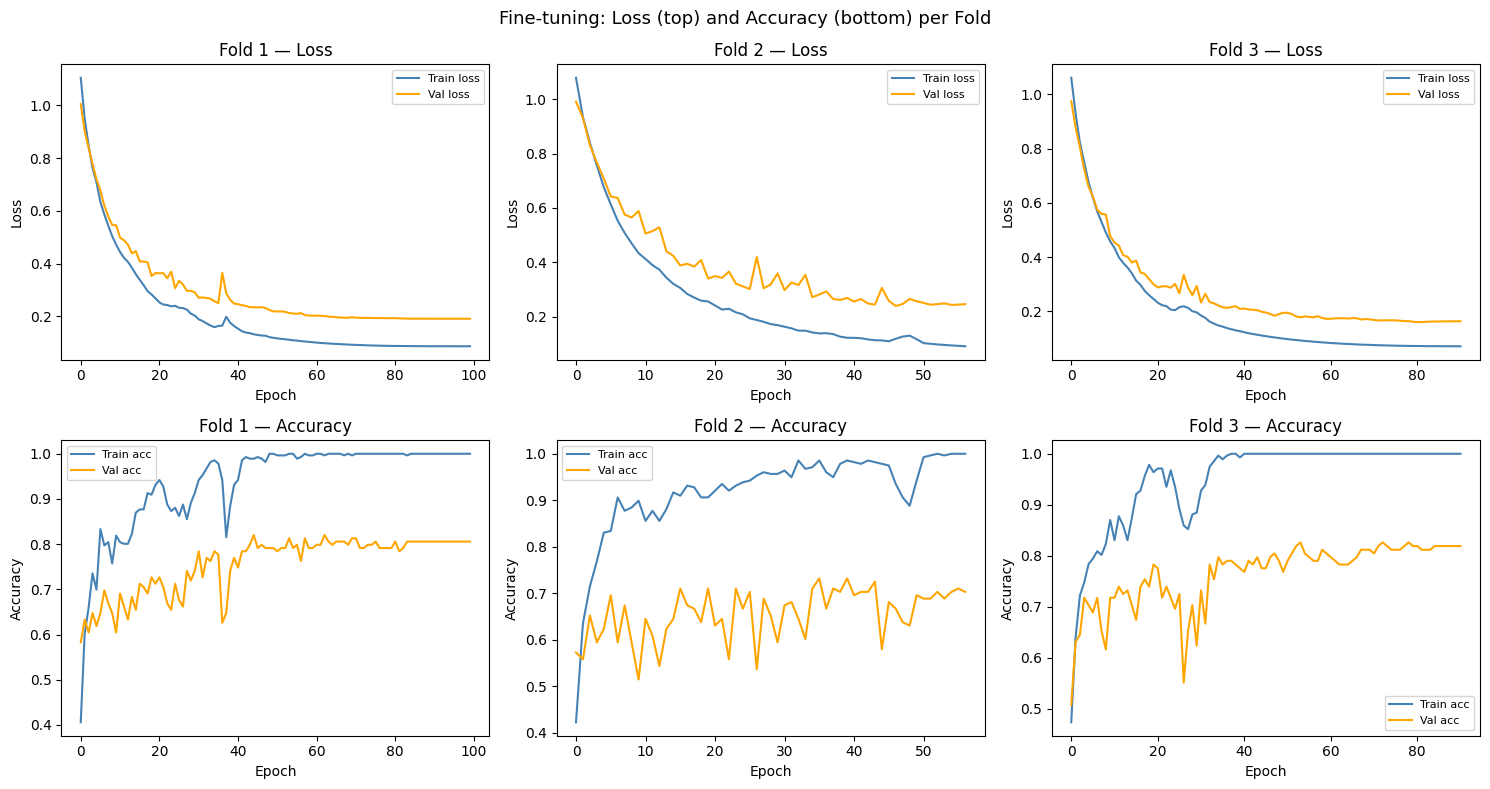

In [ ]:
# -----------------------------------------------------------------------
# 7a. Fine-tuning loss & accuracy curves per fold
# -----------------------------------------------------------------------
fig, axes = plt.subplots(2, N_SPLITS, figsize=(5 * N_SPLITS, 8))

for i, hist in enumerate(fold_histories):
    # Loss
    axes[0][i].plot(hist['loss'],     label='Train loss', color='steelblue')
    axes[0][i].plot(hist['val_loss'], label='Val loss',   color='orange')
    axes[0][i].set_title(f'Fold {i+1} — Loss')
    axes[0][i].set_xlabel('Epoch')
    axes[0][i].set_ylabel('Loss')
    axes[0][i].legend(fontsize=8)

    # Accuracy
    axes[1][i].plot(hist['accuracy'],     label='Train acc', color='steelblue')
    axes[1][i].plot(hist['val_accuracy'], label='Val acc',   color='orange')
    axes[1][i].set_title(f'Fold {i+1} — Accuracy')
    axes[1][i].set_xlabel('Epoch')
    axes[1][i].set_ylabel('Accuracy')
    axes[1][i].legend(fontsize=8)

plt.suptitle('Fine-tuning: Loss (top) and Accuracy (bottom) per Fold', fontsize=13)
plt.tight_layout()
plt.show()


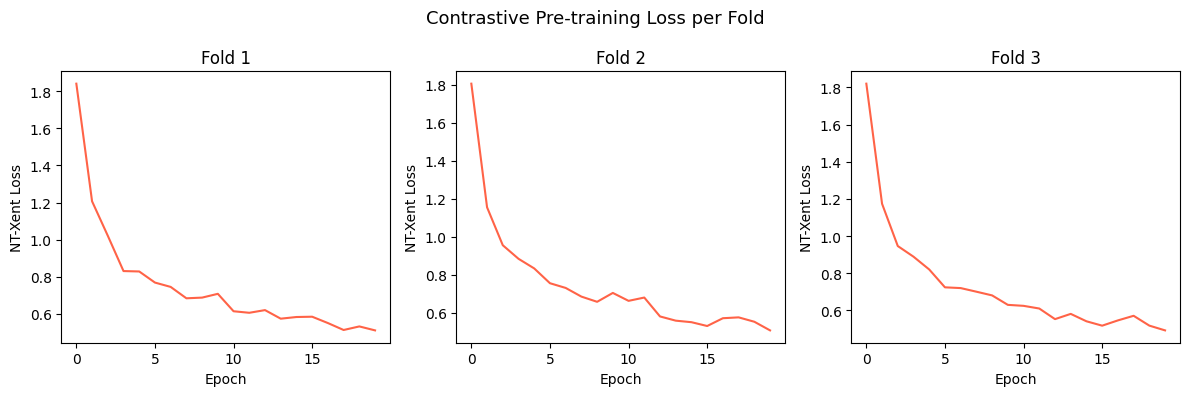

In [ ]:
# -----------------------------------------------------------------------
# 7b. Pre-training loss curves for each fold
# -----------------------------------------------------------------------
fig, axes = plt.subplots(1, N_SPLITS, figsize=(4 * N_SPLITS, 4))
for i, pt in enumerate(fold_pretrain_loss):
    axes[i].plot(pt, color='tomato')
    axes[i].set_title(f'Fold {i+1}')
    axes[i].set_xlabel('Epoch')
    axes[i].set_ylabel('NT-Xent Loss')
plt.suptitle('Contrastive Pre-training Loss per Fold', fontsize=13)
plt.tight_layout()
plt.show()

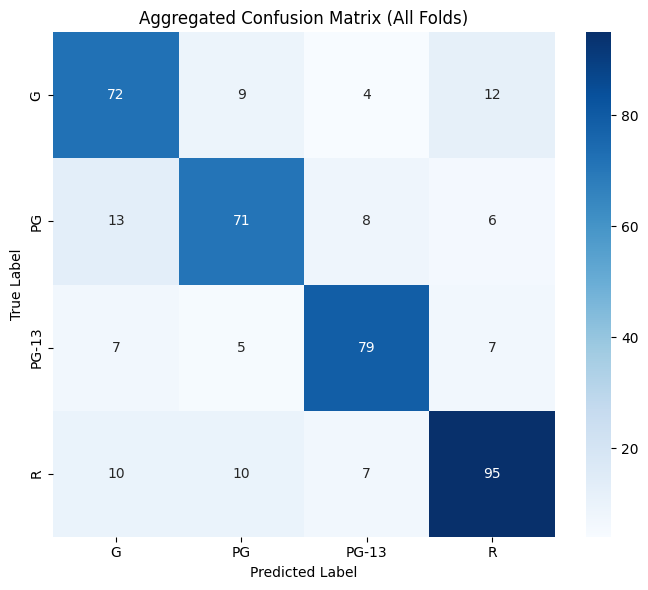


Aggregated Classification Report:
              precision    recall  f1-score   support

           G       0.71      0.74      0.72        97
          PG       0.75      0.72      0.74        98
       PG-13       0.81      0.81      0.81        98
           R       0.79      0.78      0.79       122

    accuracy                           0.76       415
   macro avg       0.76      0.76      0.76       415
weighted avg       0.76      0.76      0.76       415



In [ ]:
# -----------------------------------------------------------------------
# 7c. Aggregated Confusion Matrix  (all folds combined)
# -----------------------------------------------------------------------
cm = confusion_matrix(all_y_true, all_y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES_LIST, yticklabels=CLASSES_LIST)
plt.title('Aggregated Confusion Matrix (All Folds)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

print('\nAggregated Classification Report:')
print(classification_report(all_y_true, all_y_pred, target_names=CLASSES_LIST))

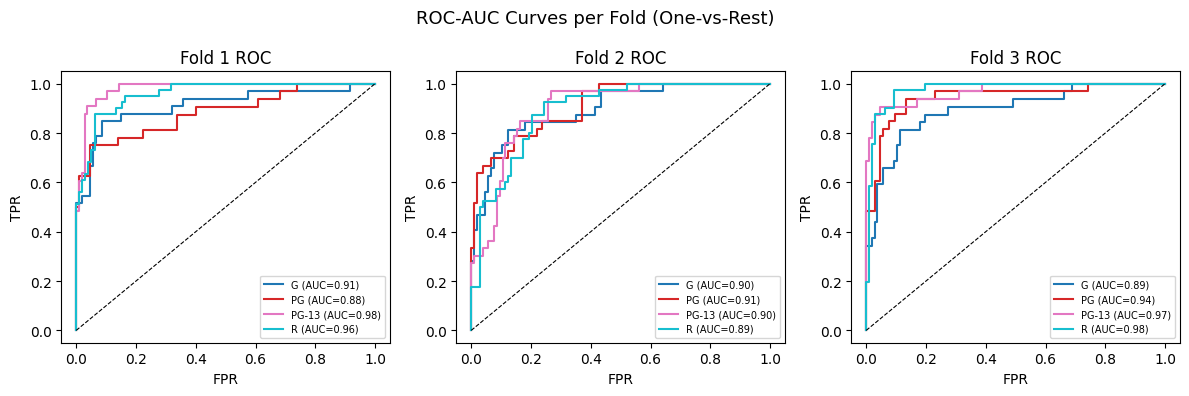

In [ ]:
# -----------------------------------------------------------------------
# 7d. ROC-AUC per fold
# -----------------------------------------------------------------------
fig, axes = plt.subplots(1, N_SPLITS, figsize=(4 * N_SPLITS, 4))
colors = plt.cm.tab10(np.linspace(0, 1, len(CLASSES_LIST)))

for fold_i, y_probs_fold in enumerate(all_y_probs):
    # Gather true labels for this fold
    fold_size  = len(y_probs_fold)
    start      = sum(len(all_y_probs[j]) for j in range(fold_i))
    y_true_fold = np.array(all_y_true[start : start + fold_size])
    y_true_oh   = to_categorical(y_true_fold, num_classes=len(CLASSES_LIST))

    ax = axes[fold_i]
    for c_i, cls_name in enumerate(CLASSES_LIST):
        try:
            fpr, tpr, _ = roc_curve(y_true_oh[:, c_i], y_probs_fold[:, c_i])
            auc_val     = roc_auc_score(y_true_oh[:, c_i], y_probs_fold[:, c_i])
            ax.plot(fpr, tpr, color=colors[c_i],
                    label=f'{cls_name} (AUC={auc_val:.2f})')
        except ValueError:
            pass  # Skip class if only one label in test fold

    ax.plot([0,1],[0,1],'k--', linewidth=0.8)
    ax.set_title(f'Fold {fold_i+1} ROC')
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.legend(fontsize=7)

plt.suptitle('ROC-AUC Curves per Fold (One-vs-Rest)', fontsize=13)
plt.tight_layout()
plt.show()

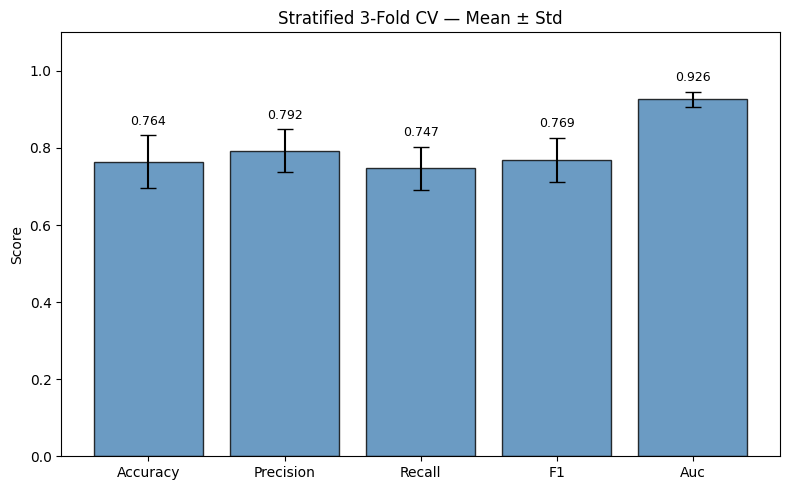

In [ ]:
# -----------------------------------------------------------------------
# 7e. Metric bar chart: mean ± std across folds
# -----------------------------------------------------------------------
metric_means = {k: np.mean([m[k] for m in fold_metrics]) for k in metrics_keys}
metric_stds  = {k: np.std( [m[k] for m in fold_metrics]) for k in metrics_keys}

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(metrics_keys))
bars = ax.bar(x, [metric_means[k] for k in metrics_keys],
              yerr=[metric_stds[k] for k in metrics_keys],
              color='steelblue', alpha=0.8, capsize=6, edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels([k.capitalize() for k in metrics_keys])
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title(f'Stratified {N_SPLITS}-Fold CV — Mean ± Std')
for bar, k in zip(bars, metrics_keys):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + metric_stds[k] + 0.02,
            f"{metric_means[k]:.3f}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()